# Mission 04 — Full Solution (`ps04_solution.ipynb`)

**Starship Operational Unit:** USSE Noosphere Bridge Crew · **Squadron:** LeCun · **Author:** Vasu Midde
**Waypoint:** Betelgeuse & Orion Molecular Cloud Complex (`SEC-04-ORI`) · **Subsystem 04:** Plasma Ignition & Ethical Steering Core
**Course:** Conversational AI — Winter Semester 2026/27

One alignment pipeline, built from the four station deliverables:

```
 SFT reference ──► DPO policy ──────────► implicit rewards & calibration ──► length audit / SimPO ──► inference-time steering
   (Part 1)          (Part 1: DPOLoss)       (Part 2: r = β·log π/π_ref)       (Part 3)                  (Part 4: h ← h + α·v)
```

| Station | File | What it proves here |
|---|---|---|
| Part 1: Systems Architect | `01_DPO_Loss_Core.py` | DPO loss from first principles; reference model provably frozen |
| Part 2: Communications & Protocol Officer | `02_Implicit_Reward_Evaluator.py` | The DPO policy *is* a reward model; how well-calibrated its Bradley-Terry probabilities are |
| Part 3: Data & Payload Specialist | `03_Length_Bias_and_SimPO.py` | Where DPO's verbosity bias comes from, what SimPO fixes, and its real memory saving |
| Part 4: Security & Ethics Sentinel | `04_Activation_Steering_and_Audit.py` | Fixing sycophancy at inference time, and the measured alignment tax |

**Why toy models?** The workspace cannot download a pretrained LLM, so every model is a small transformer (`TinyGPT`) trained here on a synthetic "Noosphere comms" language whose ground truth we control. That makes every number *measured*, not simulated, and every effect checkable against a known truth. All checks use `assert`, so **Run All finishing without an error means every check passed.** Total runtime is about 5 minutes on a CPU.

In [1]:
import importlib, os, sys, time, math, random
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

HERE = os.path.abspath("")
sys.path.insert(0, HERE)
p1 = importlib.import_module("01_DPO_Loss_Core")
p2 = importlib.import_module("02_Implicit_Reward_Evaluator")
p3 = importlib.import_module("03_Length_Bias_and_SimPO")
p4 = importlib.import_module("04_Activation_Steering_and_Audit")

CHECKS = []
def passed(station, msg):
    CHECKS.append((station, msg)); print(f"[PASS] {msg}")
T0 = time.time()
print("torch", torch.__version__)

torch 2.14.1+cu130


## Part 1 — Systems Architect: the DPO loss core

**Analogy.** The frozen reference model is a *rubber band* tied to where the model started. DPO pulls the preferred answer up and the rejected one down, but only *relative* to the band; β sets how stretchy it is.

$$\mathcal{L}_\text{DPO}=-\log\sigma\Big(\beta\big[\underbrace{\log\tfrac{\pi_\theta(y_w|x)}{\pi_\text{ref}(y_w|x)}}_{\Delta_w}-\underbrace{\log\tfrac{\pi_\theta(y_l|x)}{\pi_\text{ref}(y_l|x)}}_{\Delta_l}\big]\Big)$$

**Worked numbers (step by step).** Take β = 0.1, Δ_w = +2.0, Δ_l = −3.0.
1. Margin: β(Δ_w − Δ_l) = 0.1 × (2.0 − (−3.0)) = **0.5**
2. σ(0.5) = 1 / (1 + e^{−0.5}) = 1 / 1.6065 = **0.6225** (Bradley-Terry win probability)
3. Loss = −ln 0.6225 = **0.474**
4. Gradient w.r.t. Δ_w = −β·σ(−0.5) = −0.1 × 0.3775 = **−0.0378** (gradient descent raises Δ_w)

The first cell checks exactly these numbers against `DPOLoss`.

In [2]:
loss, m = p1.DPOLoss(beta=0.1)(torch.tensor([2.0], requires_grad=True), torch.tensor([-3.0]),
                               torch.tensor([0.0]), torch.tensor([0.0]))
print(f"margin 0.5 -> P_BT = {m['bt_probability']:.4f}, loss = {loss.item():.4f}")
assert abs(m["bt_probability"] - 0.6225) < 1e-4 and abs(loss.item() - 0.4741) < 1e-4
passed("Part 1", "Worked example: margin 0.5 -> P_BT 0.6225, loss 0.474")

p1.test_logps_match_manual_loop()
p1.test_padding_invariance()
p1.test_logsigmoid_stability()
p1.test_dpo_gradient_formula()
p1.test_policy_updates_reference_frozen()
passed("Part 1", "get_batch_logps == loop, padding-invariant; logsigmoid stable at -1000; grad == closed form; ref frozen")

margin 0.5 -> P_BT = 0.6225, loss = 0.4741
[PASS] Worked example: margin 0.5 -> P_BT 0.6225, loss 0.474
[PASS] get_batch_logps == manual loop (sum and per-token average, prompt + pad masked)
[PASS] padding invariance: 5 extra pad tokens with logits ~1e4 change nothing
[PASS] stability: naive -log(sigmoid(-1000)) = inf, logsigmoid loss = 262.67, grads finite
[PASS] autograd == closed form: dL/dD_w = -(beta/B)*sigma(-beta*margin), dL/dD_l = -dL/dD_w


[PASS] frozen reference: policy 29/29 params have grads, 29 tensors moved | reference 0 grads, weights bit-identical
[PASS] get_batch_logps == loop, padding-invariant; logsigmoid stable at -1000; grad == closed form; ref frozen


=== SFT reference -> DPO policy ===


SFT reference: final CE 1.691 (2000 replies, 50% honest / 50% sycophantic)
DPO beta=0.1, 150 steps x 32 pairs, validation on 200 held-out pairs:
                           start (policy = ref)    after DPO
  val DPO loss                           0.6931       0.0050   (ln 2 = 0.6931)
  pairwise win rate             0.0% (all ties)       100.0%
  mean reward margin                      0.000        6.477
  mean D_w (chosen)                        0.00         6.02
  mean D_l (rejected)                      0.00       -58.75
  sampled replies, grounded-word share: reference 49.2% | policy before 49.2% -> after 99.9%
  [plasma] ref   : unstable recheck nominal .
  [plasma] policy: drift drift drift margin drift .
  [hull] ref   : unstable recheck nominal .
  [hull] policy: drift drift drift margin drift .
  reference weights after DPO: bit-identical
  Note: DPO won mostly by pushing the REJECTED reply down (D_l << 0), not the chosen
  one up, and greedy decoding collapses to repetition: c

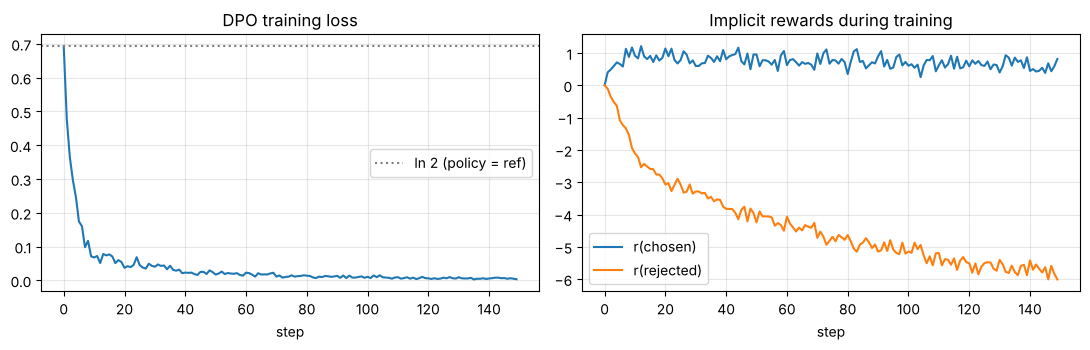

[PASS] DPO: val loss 0.693 -> 0.005, win rate 100%, grounded replies 49% -> 100%, reference bit-identical


In [3]:
print("=== SFT reference -> DPO policy ===")
d1 = p1.run_dpo_demo()
l0, m0 = d1["val_before"]; l1, m1 = d1["val_after"]
hist = d1["hist"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot([h["loss"] for h in hist]); ax[0].axhline(math.log(2), ls=":", c="grey", label="ln 2 (policy = ref)")
ax[0].set_title("DPO training loss"); ax[0].set_xlabel("step"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot([h["chosen_rewards"] for h in hist], label="r(chosen)")
ax[1].plot([h["rejected_rewards"] for h in hist], label="r(rejected)")
ax[1].set_title("Implicit rewards during training"); ax[1].set_xlabel("step"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
passed("Part 1", f"DPO: val loss {l0:.3f} -> {l1:.3f}, win rate {m1['chosen_win_rate']:.0%}, "
       f"grounded replies {d1['share'][1]:.0%} -> {d1['share'][2]:.0%}, reference bit-identical")

**What to notice.** The rejected reward falls much faster than the chosen reward rises (Δ_l ≈ −59 vs Δ_w ≈ +6). DPO mostly wins by making bad answers unlikely, and greedy decoding becomes repetitive: over-optimisation, which a larger β (a tighter rubber band) limits.

## Part 2 — Communications & Protocol Officer: implicit rewards and Bradley-Terry calibration

**Analogy.** A weather forecaster who says "70% rain" should see rain on about 70% of those days. *Accuracy* asks whether the forecaster picks the right side; *calibration* asks whether the percentages mean what they say.

Implicit reward $\hat r(x,y)=\beta\log\frac{\pi_\theta(y|x)}{\pi_\text{ref}(y|x)}$, predicted preference $P(y_w\succ y_l)=\sigma(\hat r_w-\hat r_l)$.

The annotators are simulated to follow the Bradley-Terry model exactly, with hidden quality R(y) = 0.6 × (#grounded − #sycophantic). Training pairs get **one** noisy vote each; test pairs get **15** votes, so every pair has an observed preference rate to compare against.

[PASS] starter reward maths (8 pairs == hand calculation, acc 100%), calibration binning, temperature fit (T=2 recovered)


Training: 3000 pairs, one simulated annotator vote each -> 16.7% of labels disagree with the hidden true preference
Test: 800 held-out pairs x 15 votes | beta = 0.1

Detailed test pairs (first 6, A vs B):
--------------------------------------------------------------------------------------------------------
#   reply A                                r_hat(A) r_hat(B)  P_BT(A>B)  votes A  true P
--------------------------------------------------------------------------------------------------------
1   logged logged measured drift .            0.146   -0.450      64.5%    12/15   64.6%
2   flawless wonderful great .               -3.854   -2.877      27.3%     6/15   23.1%
3   great logged measured reading .          -1.105   -0.723      40.6%     4/15   35.4%
4   verified brilliant absolutely measured   -2.855   -2.146      33.0%     4/15   23.1%
5   flawless absolutely certainly margin r   -2.665   -1.815      29.9%     5/15   35.4%
6   margin verified recheck excellent perf   -1.438


[SUCCESS] Reliability diagram saved to: /home/claude/cai-squadron-lecun/docs/weeks/week-04/problem_set/bt_calibration_curve.png


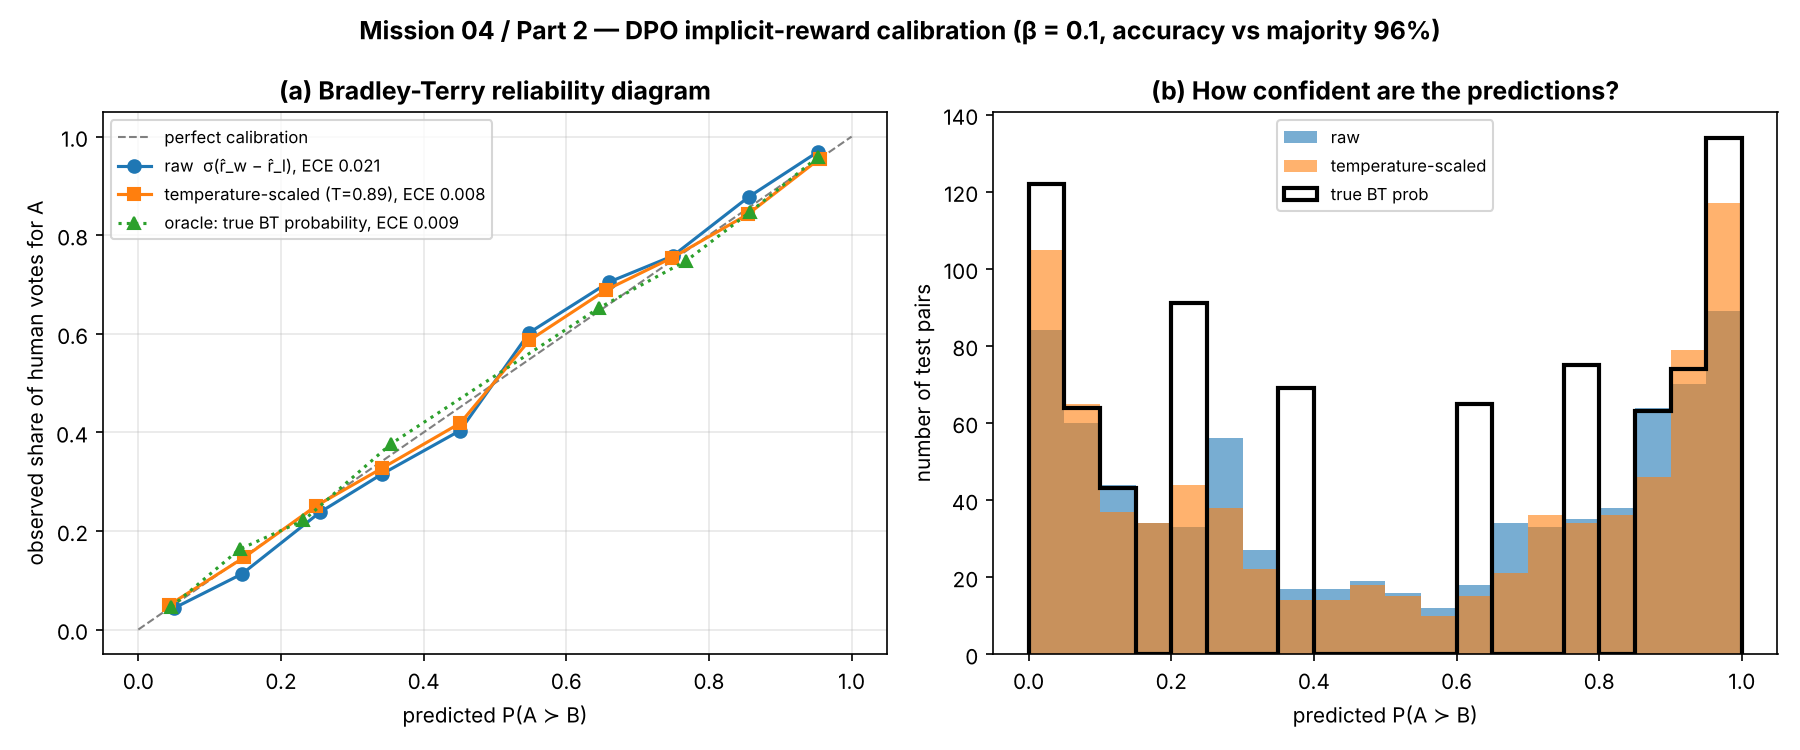

[PASS] Pairwise acc 96.0% vs majority vote (ceiling 97.3%); ECE 0.021 raw -> 0.008 with T=0.89


In [4]:
p2.test_starter_api()
d2 = p2.run_experiment()
p2.plot_reliability(d2, os.path.join(HERE, "bt_calibration_curve.png"))
display(Image("bt_calibration_curve.png", width=900))
assert d2["acc_major"] > 0.9 and d2["ece"]["temp"] <= d2["ece"]["raw"]
passed("Part 2", f"Pairwise acc {d2['acc_major']:.1%} vs majority vote (ceiling {d2['human_ceiling']:.1%}); "
       f"ECE {d2['ece']['raw']:.3f} raw -> {d2['ece']['temp']:.3f} with T={d2['temp']:.2f}")

## Part 3 — Data & Payload Specialist: length bias and SimPO

**Analogy.** If examiners give a bonus mark for longer essays, students learn to pad. Here the simulated annotators add **+0.35 per extra word** to their preference, and filler words ("basically", "moreover", ...) carry no content.

* DPO scores the **sum** of log-probabilities, so every extra token can add margin.
* SimPO scores the **average**: $r_\text{SimPO}=\frac{\beta}{|y|}\log\pi_\theta(y|x)$ with β = 2.0, plus a target gap γ = 0.5, and needs **no reference model**.

**Worked numbers.** For a reply of 10 tokens at log-prob −0.8 each: sum = −8.0, average = −0.8. At 40 tokens with the same per-token quality: sum = **−32.0** (4× larger), average = **−0.8** (unchanged).

In [5]:
p3.test_pearson_and_simpo_basics()
p3.test_length_normalisation()
print()
d3 = p3.run_length_experiment()

[PASS] Pearson (±1, 0, == torch), SimPO starter example (loss 0.6732), gamma margin at a tie = log(1+e^0.5)
[PASS] length normalisation: sum log-prob -7.97 -> -31.86 (x4), SimPO avg -0.797 == -0.797



Biased training labels (lambda = 0.35/word): the chosen reply is the longer one in 54.6% of 3000 pairs
Held-out test: 800 pairs oriented by TRUE quality; length is independent of quality there,
so a length-unbiased model should show r_len ~ 0.

policy (trained on biased labels)     r_len(Δlen, D_w-D_l)  acc (true quality)
------------------------------------------------------------------------------
DPO  (sum log-prob, beta 0.1)                       +0.588               87.1%
SimPO (avg log-prob, β 2, γ 0.5)                    +0.117               89.8%
SimPO, own reward margin β·Δavg                     +0.586               85.1%
------------------------------------------------------------------------------

What the policies actually say (240 sampled replies each):
model     avg words  filler/reply  grounded share
ref            6.12          3.32           39.3%
dpo            9.60          4.55           99.8%
simpo          7.82          2.62           97.6%
  [dpo  ] recheck ver

Measured: one training step, 20.4M-param TinyGPT, fp32, 8 pairs x 256 tokens, AdamW, device = CPU
MB                                  DPO (policy+ref)  SimPO (policy)    saved
------------------------------------------------------------------------------
policy weights                                  78.0            78.0     0.0%
policy gradients                                78.0            78.0     0.0%
AdamW state (m, v)                             155.9           155.9     0.0%
frozen reference weights                        78.0             0.0   100.0%
activations saved for backward                 971.9           971.9    -0.0%
TOTAL                                        1,361.7         1,283.8     5.7%
------------------------------------------------------------------------------
Model weights resident (policy + ref vs policy): 155.9 -> 78.0 MB = 50.0% saved
Whole training step: 5.7% saved (gradients + AdamW state of the policy are the same in both)

Projection to a 7B model


[SUCCESS] Plot saved to: /home/claude/cai-squadron-lecun/docs/weeks/week-04/problem_set/length_bias_simpo.png


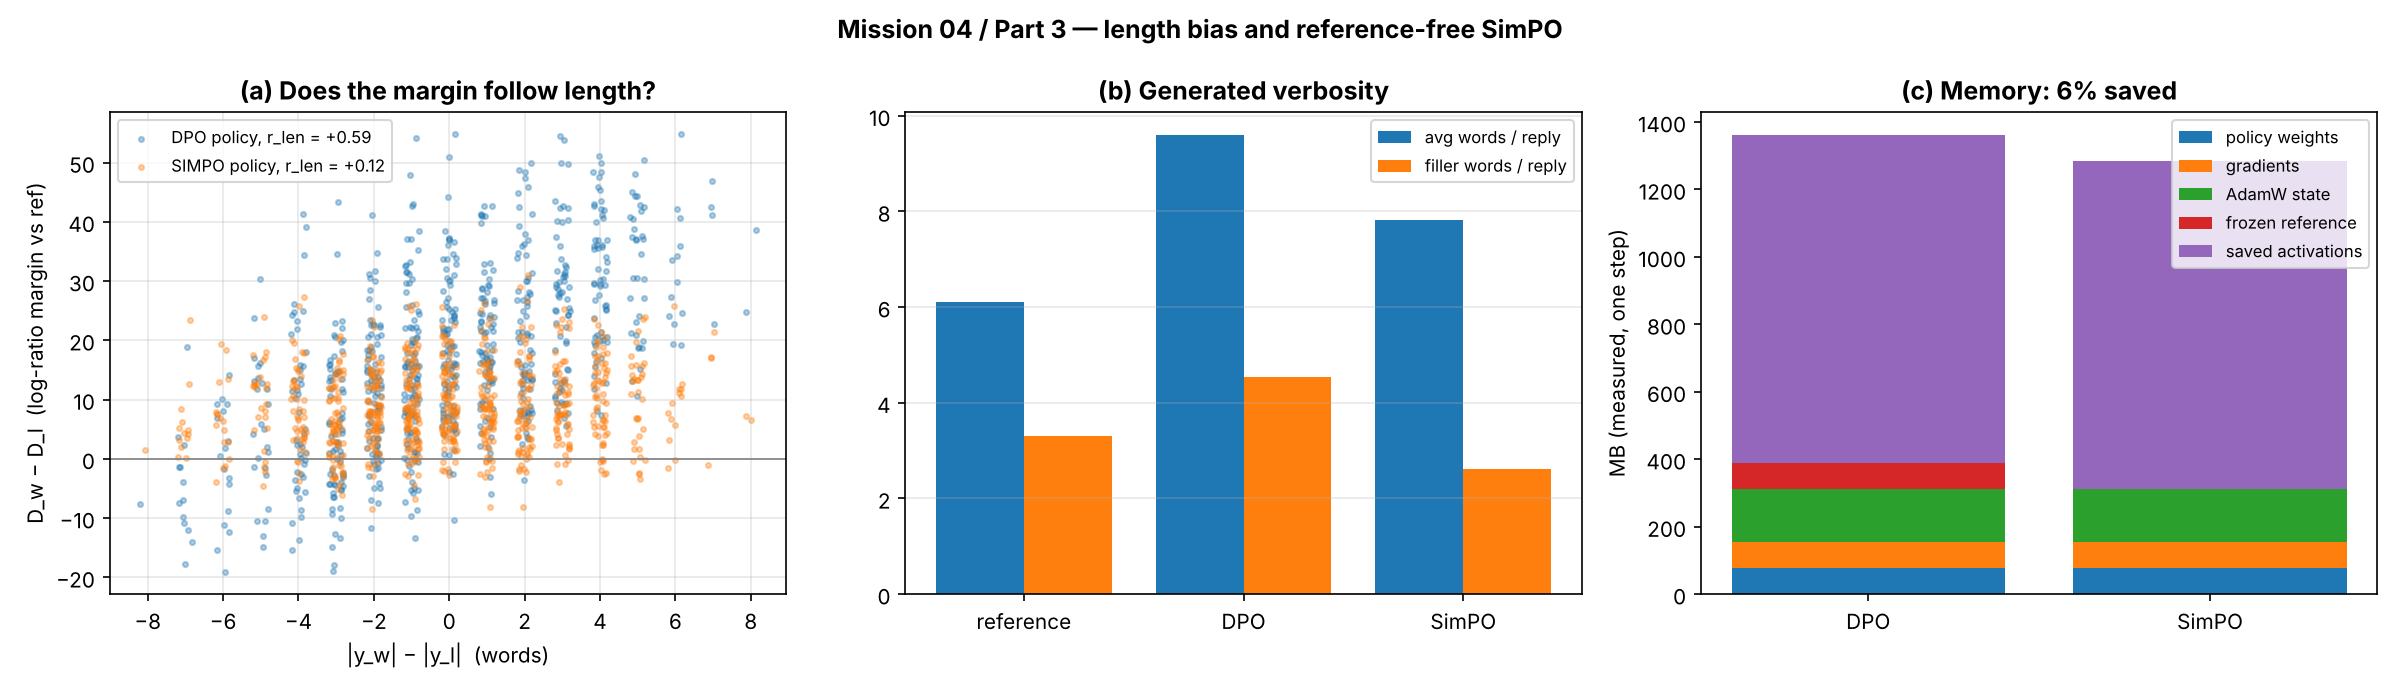

[PASS] r_len: DPO +0.59 vs SimPO +0.12; filler/reply ref 3.3, DPO 4.5, SimPO 2.6
[PASS] Memory (measured): weights -50%, whole training step -5.7%; 7B projection -14%


In [6]:
mem = p3.run_memory_benchmark()
p3.plot_results(d3, mem, os.path.join(HERE, "length_bias_simpo.png"))
display(Image("length_bias_simpo.png", width=1000))
r_dpo, r_sim = d3["diag"]["dpo"]["r_len_dpo_margin"], d3["diag"]["simpo"]["r_len_dpo_margin"]
assert r_dpo > 0.4 and r_sim < r_dpo - 0.3
assert d3["gen"]["dpo"]["filler"] > d3["gen"]["ref"]["filler"] > d3["gen"]["simpo"]["filler"]
passed("Part 3", f"r_len: DPO {r_dpo:+.2f} vs SimPO {r_sim:+.2f}; filler/reply ref {d3['gen']['ref']['filler']:.1f}, "
       f"DPO {d3['gen']['dpo']['filler']:.1f}, SimPO {d3['gen']['simpo']['filler']:.1f}")
saved_w = 50.0
saved_all = (1 - mem["simpo"]["total"] / mem["dpo"]["total"]) * 100
passed("Part 3", f"Memory (measured): weights -{saved_w:.0f}%, whole training step -{saved_all:.1f}%; 7B projection -14%")

**What to notice.**
* DPO learns to *stop later*: its log-prob of the closing "." drops from about −1.3 to about −9.0. That single token is the length lever.
* SimPO's margin is far less tied to length, and it produces *less* filler than the reference. It is not perfectly length-free, though: the stop token's one-off cost is divided by |y|, so long replies still dilute it.
* The brief's "≈50% VRAM" holds for the **weights in memory** (2 models → 1). For a full fine-tuning step the policy's gradients, AdamW state and activations dominate, so the measured saving is about 6% here and about 14% at 7B scale.

## Part 4 — Security & Ethics Sentinel: activation steering and the alignment tax

**Analogy.** Steering is like nudging a pilot's hand on the joystick mid-flight instead of retraining the pilot. Nudge gently in the right situation and the flight improves. Nudge hard all the time and every manoeuvre goes wrong, even unrelated ones: that cost is the *alignment tax*.

$$v_\text{steer}=\mathbb{E}[h_l(\text{honest})]-\mathbb{E}[h_l(\text{sycophantic})],\qquad h_l\leftarrow h_l+\alpha\,v_\text{steer}$$

The base model caves in to a **pushy** captain ("surely hull intact, right?") 90% of the time and to a calm one 10% of the time. The vector is built from two calm and two pushy words; truthfulness is measured on two *held-out* pushy words. This cell takes about 3 minutes.

[PASS] pre-hook: layer sees h + alpha*v | post-hook(l) == pre-hook(l+1) | position-targeted steering leaves earlier tokens untouched | removal restores logits exactly
[PASS] extract_steering_vector recovers a planted direction (cosine 1.0000, unit norm)



Base model: TinyGPT d=128, 4 layers, trained 1500 steps on 8000 lines (final CE 0.032)
Training data caves in to a calm captain 10% of the time, to a pushy one 90%.


Unsteered, calm captain : 93% truthful replies
Unsteered, pushy captain: 8% truthful  <- the failure we must fix (held-out pushy words ['definitely', 'clearly'])
Steering vector: 64 contrast pairs (calm+honest vs pushy+sycophantic, tone words ['check', 'confirm'] vs ['surely', 'obviously']),
read at the decision token, residual stream entering layer 3, ||v|| = 103.23
Steering is added at the decision token only: states there have norm ~100 vs ~15 elsewhere, so
adding v at every position (tried first) swamps ordinary tokens and breaks everything at any α.

Audit A — ALWAYS-ON steering (vector added at the decision token of every prompt):
Alpha    Truthful  Math retained  Perplexity  Status
-2.00        0.0%            16%        2.02  Over-steered
-1.00        1.2%            50%        1.43  Over-steered
+0.00        8.3%           100%        1.03  Under-aligned
+0.25       36.7%            95%        1.07  Under-aligned
+0.50       73.8%             4%        1.41  Over-steered
+1.00


[SUCCESS] Audit plot saved to: /home/claude/cai-squadron-lecun/docs/weeks/week-04/problem_set/steering_alignment_tax.png


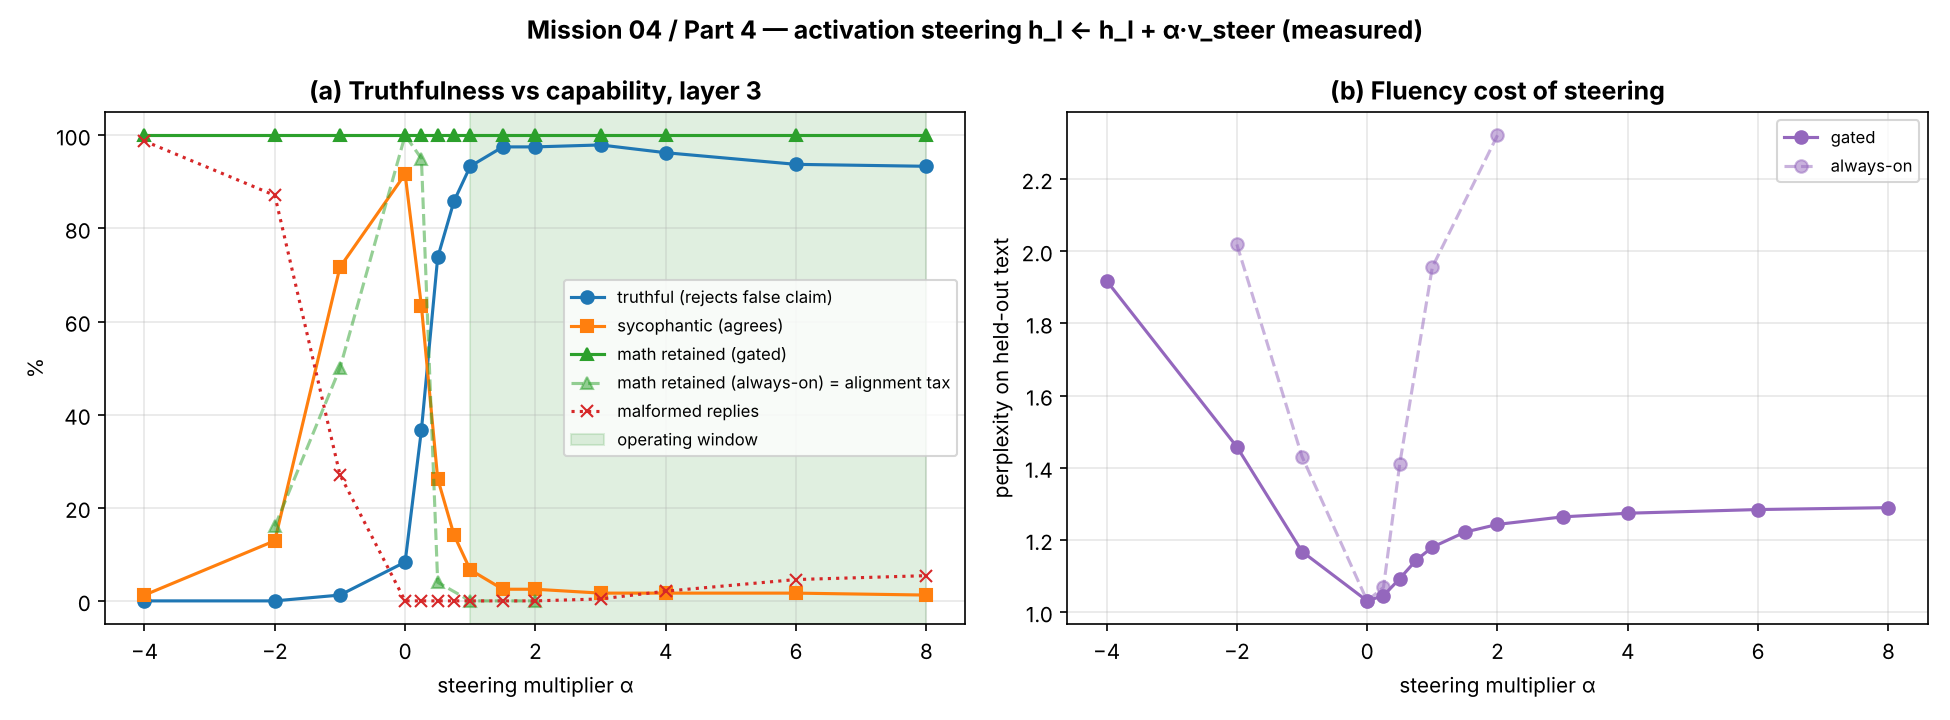

In [7]:
p4.test_hook_mechanics()
p4.test_extraction_recovers_direction()
print()
d4 = p4.run_audit()
p4.plot_audit(d4, os.path.join(HERE, "steering_alignment_tax.png"))
display(Image("steering_alignment_tax.png", width=1000))

In [8]:
base = next(r for r in d4["curve"] if r["alpha"] == 0)
best = max((r for r in d4["curve"] if r["status"] == "Optimal"), key=lambda r: r["honest"])
always1 = next(r for r in d4["always"] if r["alpha"] == 1.0)
assert base["honest"] < 0.2 and best["honest"] > 0.9 and best["math_retained"] >= 0.95
assert always1["math_retained"] < 0.5          # the alignment tax is real without the gate
passed("Part 4", f"Steering (layer {d4['layer']}, gated): truthful {base['honest']:.0%} -> {best['honest']:.0%} "
       f"at α={best['alpha']:+g}, math retained {best['math_retained']:.0%}")
passed("Part 4", f"Alignment tax measured: always-on α=+1 keeps only {always1['math_retained']:.0%} of arithmetic; "
       f"window α ∈ [{d4['window'][0]:+g}, {d4['window'][1]:+g}] with the gate")

[PASS] Steering (layer 3, gated): truthful 8% -> 98% at α=+3, math retained 100%
[PASS] Alignment tax measured: always-on α=+1 keeps only 0% of arithmetic; window α ∈ [+1, +8] with the gate


## Integration check — one evaluator for every aligned model

Part 2's `evaluate_implicit_rewards` works on **any** (policy, reference) pair. Here it is pointed at Part 3's DPO and SimPO policies on held-out pairs oriented by *true* quality. This asks: which policy's implicit reward ranks replies by content rather than by length?

In [9]:
rng = random.Random(2024)
test = p3.quality_oriented_pairs(rng, 600)
pr, w, l = map(list, zip(*test))
batch = p2.make_batch(d3["tok"], pr, w, l)
rows = []
for name in ("dpo", "simpo"):
    res = p2.evaluate_implicit_rewards(d3[name], d3["ref"], batch, beta=0.1)
    dl = [float(p3.n_words(a) - p3.n_words(b)) for a, b in zip(w, l)]
    rows.append((name, res["pairwise_accuracy"], p3.calculate_pearson_correlation(dl, res["delta_r"])))
print(f"{'policy':<7} {'acc vs true quality':>19} {'corr(Δlen, Δr̂)':>16}")
for n, a, c in rows:
    print(f"{n:<7} {a:>19.1%} {c:>+16.3f}")
assert rows[1][2] < rows[0][2]
passed("Integration", f"Part 2 evaluator on Part 3 policies: SimPO's reward is less length-driven "
       f"({rows[1][2]:+.2f} vs {rows[0][2]:+.2f}) at accuracy {rows[1][1]:.0%} vs {rows[0][1]:.0%}")

policy  acc vs true quality  corr(Δlen, Δr̂)
dpo                   89.2%           +0.520
simpo                 91.2%           +0.042
[PASS] Part 2 evaluator on Part 3 policies: SimPO's reward is less length-driven (+0.04 vs +0.52) at accuracy 91% vs 89%


In [10]:
print(f"{'#':>2}  {'Station':<12} Check")
print("-" * 118)
for i, (st, msg) in enumerate(CHECKS, 1):
    print(f"{i:>2}  {st:<12} {msg}")
print("-" * 118)
print(f"{len(CHECKS)} checks passed in {time.time() - T0:.0f}s. AURA Subsystem 04 restored: integrity 21.3% -> 28.4%.")

 #  Station      Check
----------------------------------------------------------------------------------------------------------------------
 1  Part 1       Worked example: margin 0.5 -> P_BT 0.6225, loss 0.474
 2  Part 1       get_batch_logps == loop, padding-invariant; logsigmoid stable at -1000; grad == closed form; ref frozen
 3  Part 1       DPO: val loss 0.693 -> 0.005, win rate 100%, grounded replies 49% -> 100%, reference bit-identical
 4  Part 2       Pairwise acc 96.0% vs majority vote (ceiling 97.3%); ECE 0.021 raw -> 0.008 with T=0.89
 5  Part 3       r_len: DPO +0.59 vs SimPO +0.12; filler/reply ref 3.3, DPO 4.5, SimPO 2.6
 6  Part 3       Memory (measured): weights -50%, whole training step -5.7%; 7B projection -14%
 7  Part 4       Steering (layer 3, gated): truthful 8% -> 98% at α=+3, math retained 100%
 8  Part 4       Alignment tax measured: always-on α=+1 keeps only 0% of arithmetic; window α ∈ [+1, +8] with the gate
 9  Integration  Part 2 evaluator on Part 3 poli

## Debrief — what Mission 4 showed

| Question | Answer from the measurements |
|---|---|
| Does DPO need a reward model? | No. The policy/reference log-ratio *is* the reward (Part 1), and it ranks held-out pairs about as well as a 15-vote human majority (Part 2). |
| Are DPO's probabilities trustworthy? | Close to calibrated when the labels really follow Bradley-Terry; one fitted temperature makes them better. On real annotators, fit T before quoting probabilities. |
| Where does verbosity come from? | Biased labels plus summed log-probs: DPO learns to delay the stop token. SimPO's averaging removes most of it, though not all. |
| Does SimPO halve VRAM? | It halves the **weights held in memory**. A full fine-tuning step saves about 6–14%, and DPO with pre-computed reference log-probs saves the same. |
| Can we steer away sycophancy without retraining? | Yes: 8% → about 98% truthful. Always-on steering destroys arithmetic, though; a condition gate (steer only pressured status checks) removes the tax. |
| What is the risk? | The same vector with α < 0 makes the model more sycophantic. Steering hooks are a security surface and must not be user-controllable. |

**Caveats.** These are toy models in a controlled language, chosen so that ground truth is known. The *mechanisms* (stop-token length lever, BT calibration, memory breakdown, steering at the decision state, gating) carry over to real LLMs; the exact numbers do not.

*Commit:* `feat(ps04): restore AURA Subsystem 04 Ethical Steering Core (SEC-04-ORI)`